# Supplementary Figure 3.3: Sequential structure in bound estimates

Ports the "Regression to the mean" section of the old MATLAB `PigeonSims.m`
(`Archive/Analysis/Playpen/Old/PigeonSims.m`, lines 36–58) and uses it to ask
three follow-up questions about the `Δ|bound| ~ previous |bound|` slope ≈ −1
result from `Table_slopeAnalyses` / `Figure03_boundSummary` Panel D.

**Part 0** reproduces the original generic demo: bounds drawn i.i.d. from a
fixed generative mean with measurement noise (no true trial-to-trial change)
still produce a regression slope near −1. This establishes that slope ≈ −1 is,
by itself, consistent with a *fixed* bound plus noisy per-trial estimation —
not necessarily evidence of a truly varying bound.

**Parts 1–3** make the comparison concrete using the actual generative model
and bound-estimation pipeline (`pigeon.simulate`, `pigeon.data.get_bounds`)
rather than the abstract i.i.d. demo, matched to real subjects in **OL blocks
1–3** (raw 6-block numbering, all SNRs pooled — same block/dataset convention
as `Table_slopeAnalyses`). For each real subject, a simulated counterpart is
generated with `bound_type='fixed'`: a truly constant bound equal to that
subject's median |bound| in that block, so any trial-to-trial variability in
the simulated bound estimates comes only from step noise and the estimation
procedure.

1. Compare per-subject `Δ|bound| ~ previous |bound|` regression slopes, real
   vs. matched fixed-bound simulated data.
2. Compare per-subject SD of |bound| estimates, real vs. simulated — tests
   whether real bounds vary *more* than expected from estimation noise alone.
3. Test for sequential structure beyond lag-1 mean reversion: per-subject
   autocorrelation of |bound| at lags 1–5. Under the fixed-bound + i.i.d.-noise
   model, all lags should have autocorrelation ≈ 0; systematic deviations in
   the real data indicate genuine trial-to-trial dependency not explained by
   pure measurement noise.

Per-block numeric summaries are printed for all three analyses; a single
combined 3×3 figure (rows = analyses, columns = blocks) shows the real-vs-
simulated comparisons — no separate per-block plots. Saves to `Figure03_S03.pdf`.

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt

from pigeon.data import get_data_table, get_good_trial_array
from pigeon.simulate import get_simulated_data_table
from pigeon.pathDefaults import FIGURES_DIR

RNG = np.random.default_rng(12345)

## Part 0: Generic regression-to-mean demo

Direct port of the MATLAB `%% Regression to the mean` section. For a range of
true bound means, draw `N` i.i.d. bound *estimates* from `N(mean, std=0.1)`
(truncated to `[0, 0.8]`), then regress `diff(bounds) ~ bounds(1:end-1)`
(the **previous** value). There is no true bound change across draws — the
"trials" here are just repeated noisy measurements of one fixed number — yet
the regression slope comes out near −1 across the whole range of means, and
`-intercept/slope` recovers the true generative mean (the fixed point of the
artifact).

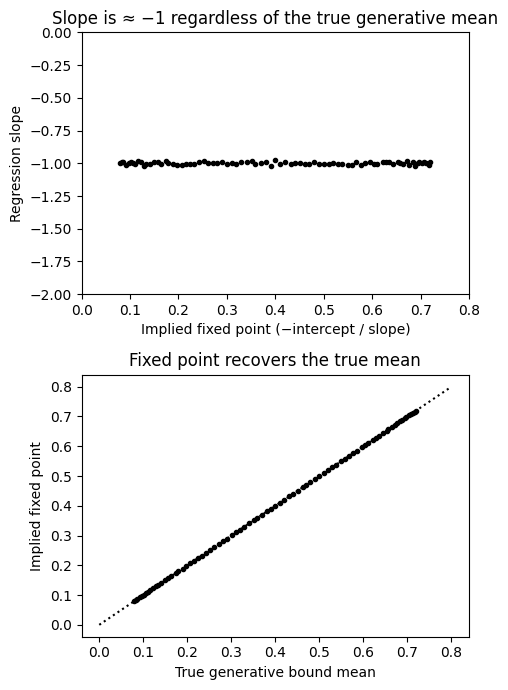

Slope across all generative means: median = -1.000, range = [-1.022, -0.972]


In [2]:
means      = np.arange(0, 0.8 + 0.01, 0.01)
STD        = 0.1
N          = 10_000

slopes     = np.full(len(means), np.nan)
intercepts = np.full(len(means), np.nan)
mean_bound = np.full(len(means), np.nan)

for mi, mean in enumerate(means):
    bounds = RNG.normal(mean, STD, N)
    bad = (bounds < 0) | (bounds > 0.8)
    while bad.any():
        bounds[bad] = RNG.normal(mean, STD, int(bad.sum()))
        bad = (bounds < 0) | (bounds > 0.8)

    delta_bounds = np.diff(bounds)
    slope, intercept, *_ = scipy.stats.linregress(bounds[:-1], delta_bounds)
    slopes[mi]     = slope
    intercepts[mi] = intercept
    mean_bound[mi] = bounds.mean()

fixed_point = -intercepts / slopes

fig, axs = plt.subplots(2, 1, figsize=(5, 7))

axs[0].plot(fixed_point, slopes, 'ko', ms=3)
axs[0].axis([0, 0.8, -2, 0])
axs[0].set_xlabel('Implied fixed point (−intercept / slope)')
axs[0].set_ylabel('Regression slope')
axs[0].set_title('Slope is ≈ −1 regardless of the true generative mean')

axs[1].plot(mean_bound, fixed_point, 'ko', ms=3)
axs[1].plot([0, 0.8], [0, 0.8], 'k:')
axs[1].set_xlabel('True generative bound mean')
axs[1].set_ylabel('Implied fixed point')
axs[1].set_title('Fixed point recovers the true mean')

plt.tight_layout()
plt.show()

print(f'Slope across all generative means: median = {np.nanmedian(slopes):.3f}, '
      f'range = [{np.nanmin(slopes):.3f}, {np.nanmax(slopes):.3f}]')

## Parts 1–3 setup: real vs. matched fixed-bound simulated data (OL blocks 1–3)

Load real OL data (raw 6-block numbering, `combine_snr=False`) once, then for
each of blocks 1–3: restrict to that block, simulate a matched counterpart
with `bound_type='fixed'` (constant bound per subject = that subject's own
median |bound| in that block; `bound_std=0`), and precompute the per-subject
|bound| arrays, slopes, SDs, and autocorrelations used by all three analyses.
Passing only one block's rows to `get_simulated_data_table` simulates just
that block per subject (matching generative SNRs and NDTs).

In [3]:
BLOCKS = [1, 2, 3]  # raw 6-block numbering, same convention as Table_slopeAnalyses

data_table_ol = get_data_table(task_type='OL', combine_snr=False)

  1: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_14h39.24.096.csv
  2: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_15h37.48.260.csv
  3: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h34.46.761.csv
  4: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h35.25.285.csv
  5: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h36.33.669.csv
  6: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h36.41.364.csv
  7: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h36.49.086.csv
  8: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 14: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_17h35.53.048.csv
 15: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_17h48.56.013.csv
 16: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_19h38.38.956.csv
 17: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h36.04.663.csv
 18: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h36.05.544.csv
 19: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h36.07.852.csv
 20: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h37.13.084.csv
 21: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 28: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h40.06.581.csv
 29: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h41.15.620.csv
 30: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h42.16.563.csv
 31: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h46.46.975.csv
 32: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h54.23.759.csv
 33: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h30.52.958.csv
 34: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h34.58.360.csv
 35: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 43: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h39.13.059.csv
 44: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h41.40.441.csv
 45: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h42.52.039.csv
 46: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h42.54.723.csv
 47: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h49.12.728.csv
 48: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_01h07.36.399.csv
 49: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_01h09.54.461.csv
 50: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 57: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h39.12.114.csv
 58: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h40.02.817.csv
 59: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h40.07.382.csv
 60: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h41.01.524.csv


In [4]:
def per_subject_bounds(df, lg):
    # Return {subject_index: sorted-by-trial |bound| array} for good trials.
    out = {}
    for subj in np.sort(df.loc[lg, 'subject_index'].dropna().unique()):
        sub = df[lg & (df['subject_index'] == subj)].sort_values('trial_number')
        ab = np.abs(sub['bound'].to_numpy(dtype=float))
        ab = ab[np.isfinite(ab)]
        if len(ab) >= 4:
            out[subj] = ab
    return out


def delta_bound_slope(ab):
    # Regress against the PREVIOUS trial's |bound| (not current) so slope = -1
    # corresponds to classical regression to the mean (matches Part 0 and the
    # corrected Table_slopeAnalyses / Figure03_boundSummary Panel D convention).
    prev, delta = ab[:-1], np.diff(ab)
    if len(prev) < 3 or np.ptp(prev) == 0:
        return np.nan
    slope, *_ = scipy.stats.linregress(prev, delta)
    return slope


MAX_LAG = 5
MIN_N   = MAX_LAG + 15

def subject_acf(ab, max_lag=MAX_LAG, min_n=MIN_N):
    if len(ab) < min_n:
        return np.full(max_lag, np.nan)
    out = np.full(max_lag, np.nan)
    for k in range(1, max_lag + 1):
        x, y = ab[:-k], ab[k:]
        if len(x) < 5 or np.ptp(x) == 0 or np.ptp(y) == 0:
            continue
        r, _ = scipy.stats.pearsonr(x, y)
        out[k - 1] = r
    return out


def med_iqr(x):
    q25, med, q75 = np.percentile(x, [25, 50, 75])
    return f'{med:.3f} [{q25:.3f}, {q75:.3f}]'

In [5]:
results = {}

for block in BLOCKS:
    real_block = data_table_ol[data_table_ol['block_index'] == block].reset_index(drop=True)
    sim_block  = get_simulated_data_table(data_table=real_block, bound_type='fixed', rng=RNG)

    good_real = get_good_trial_array(real_block) & real_block['bound'].notna()
    good_sim  = get_good_trial_array(sim_block)  & sim_block['bound'].notna()

    bounds_real = per_subject_bounds(real_block, good_real)
    bounds_sim  = per_subject_bounds(sim_block,  good_sim)
    common = sorted(set(bounds_real) & set(bounds_sim))

    slopes_real = pd.Series({s: delta_bound_slope(ab) for s, ab in bounds_real.items()})
    slopes_sim  = pd.Series({s: delta_bound_slope(ab) for s, ab in bounds_sim.items()})
    sr = slopes_real.loc[common].dropna()
    ss = slopes_sim.loc[sr.index].dropna()
    sr = sr.loc[ss.index]

    std_real = pd.Series({s: np.std(ab, ddof=1) for s, ab in bounds_real.items()})
    std_sim  = pd.Series({s: np.std(ab, ddof=1) for s, ab in bounds_sim.items()})
    pr = std_real.loc[common]
    ps = std_sim.loc[common]

    acf_real = pd.DataFrame(
        {s: subject_acf(ab) for s, ab in bounds_real.items()},
        index=np.arange(1, MAX_LAG + 1),
    ).T
    acf_sim = pd.DataFrame(
        {s: subject_acf(ab) for s, ab in bounds_sim.items()},
        index=np.arange(1, MAX_LAG + 1),
    ).T

    results[block] = dict(common=common, sr=sr, ss=ss, pr=pr, ps=ps,
                           acf_real=acf_real, acf_sim=acf_sim)

    print(f'OL block {block}: {good_real.sum()} real / {good_sim.sum()} simulated good trials, '
          f'{len(common)} subjects with usable data in both')

OL block 1: 3562 real / 2330 simulated good trials, 45 subjects with usable data in both
OL block 2: 3070 real / 2326 simulated good trials, 56 subjects with usable data in both


OL block 3: 1448 real / 1282 simulated good trials, 51 subjects with usable data in both


## Part 1: Δ|bound| ~ previous |bound| slope, real vs. simulated

Same regression as `Table_slopeAnalyses` analysis 2 / `Figure03_boundSummary`
Panel D, computed separately for real subjects and their matched fixed-bound
simulated counterparts in each block, then compared with a paired
(subject-matched) Wilcoxon signed-rank test.

In [6]:
print(f'{"block":>6} {"real slope":>22} {"sim slope":>22} {"paired p":>10} {"real vs -1 p":>13} {"sim vs -1 p":>12}')
for block in BLOCKS:
    sr, ss = results[block]['sr'], results[block]['ss']
    _, p_paired  = scipy.stats.wilcoxon(sr, ss)
    _, p_real_m1 = scipy.stats.wilcoxon(sr + 1)
    _, p_sim_m1  = scipy.stats.wilcoxon(ss + 1)
    print(f'{block:>6} {med_iqr(sr):>22} {med_iqr(ss):>22} {p_paired:>10.3g} {p_real_m1:>13.3g} {p_sim_m1:>12.3g}')

 block             real slope              sim slope   paired p  real vs -1 p  sim vs -1 p
     1 -0.970 [-1.071, -0.879] -1.063 [-1.161, -0.964]    0.00879         0.212       0.0013
     2 -0.981 [-1.073, -0.844] -1.061 [-1.125, -0.893]     0.0653         0.134         0.37
     3 -0.966 [-1.052, -0.846] -1.102 [-1.190, -0.928]     0.0571         0.111        0.048


## Part 2: SD of |bound| estimates, real vs. simulated

If real bounds vary trial-to-trial by more than measurement noise alone would
predict, the SD of |bound| estimates should be larger for real subjects than
for their matched fixed-bound simulated counterparts (same subject, same
generative SNRs/NDTs, only the true bound is fixed to a constant in the
simulation).

In [7]:
print(f'{"block":>6} {"real SD":>20} {"sim SD":>20} {"paired p":>10}')
for block in BLOCKS:
    pr, ps = results[block]['pr'], results[block]['ps']
    _, p = scipy.stats.wilcoxon(pr, ps)
    print(f'{block:>6} {med_iqr(pr):>20} {med_iqr(ps):>20} {p:>10.3g}')

 block              real SD               sim SD   paired p
     1 0.138 [0.128, 0.148] 0.126 [0.116, 0.138]   0.000387
     2 0.136 [0.124, 0.155] 0.127 [0.109, 0.145]   0.000376
     3 0.131 [0.120, 0.151] 0.130 [0.094, 0.140]    0.00401


## Part 3: Sequential structure beyond lag-1 mean reversion

Under the fixed-bound + i.i.d.-noise model, |bound| estimates on different
trials are independent draws around a constant — the autocorrelation of the
*raw* |bound| series (not the delta) should be ≈ 0 at every lag. Real bounds
may show additional structure (e.g., slow drift, momentum) that a pure
measurement-noise account of the −1 slope would not predict. Autocorrelation
is computed per subject at lags 1–5 and compared real vs. matched simulated,
lag by lag, with a paired Wilcoxon test.

In [8]:
for block in BLOCKS:
    acf_real, acf_sim, common = results[block]['acf_real'], results[block]['acf_sim'], results[block]['common']
    print(f'--- OL block {block} ---')
    print(f'{"lag":>4} {"real median":>12} {"sim median":>12} {"paired p":>10} {"real vs 0 p":>12}')
    for k in range(1, MAX_LAG + 1):
        r = acf_real[k].loc[common]
        s = acf_sim[k].loc[common]
        ok = r.notna() & s.notna()
        r_ok, s_ok = r[ok], s[ok]

        _, p_paired = scipy.stats.wilcoxon(r_ok, s_ok)
        _, p_r0     = scipy.stats.wilcoxon(r_ok)

        print(f'{k:>4} {r_ok.median():>12.3f} {s_ok.median():>12.3f} {p_paired:>10.3g} {p_r0:>12.3g}')

--- OL block 1 ---
 lag  real median   sim median   paired p  real vs 0 p
   1        0.033       -0.066    0.00358        0.128
   2        0.034       -0.037     0.0788        0.201
   3        0.014       -0.001      0.237        0.347
   4        0.025        0.002      0.761         0.53
   5        0.022        0.004      0.514       0.0462
--- OL block 2 ---
 lag  real median   sim median   paired p  real vs 0 p
   1        0.027       -0.062      0.117       0.0969
   2        0.053       -0.028     0.0263        0.027
   3        0.014       -0.049     0.0103        0.502
   4       -0.019        0.030      0.124        0.374
   5       -0.036       -0.006      0.723        0.129
--- OL block 3 ---
 lag  real median   sim median   paired p  real vs 0 p
   1        0.061       -0.119     0.0137       0.0753
   2        0.016       -0.030      0.633        0.668
   3       -0.015       -0.106    0.00702        0.668
   4        0.020        0.003      0.903        0.865
   5    

## Combined figure: real vs. simulated, all three analyses × blocks 1–3

Rows: `Δ|bound| ~ previous |bound|` slope, SD of |bound|, lag-1 autocorrelation.
Columns: OL blocks 1–3. Each panel plots real (y) vs. matched fixed-bound
simulated (x) per subject; the dotted line is the identity `y = x`. Points near
the identity line indicate the real data are consistent with the fixed-bound +
noise null; systematic offsets indicate genuine differences from that null.

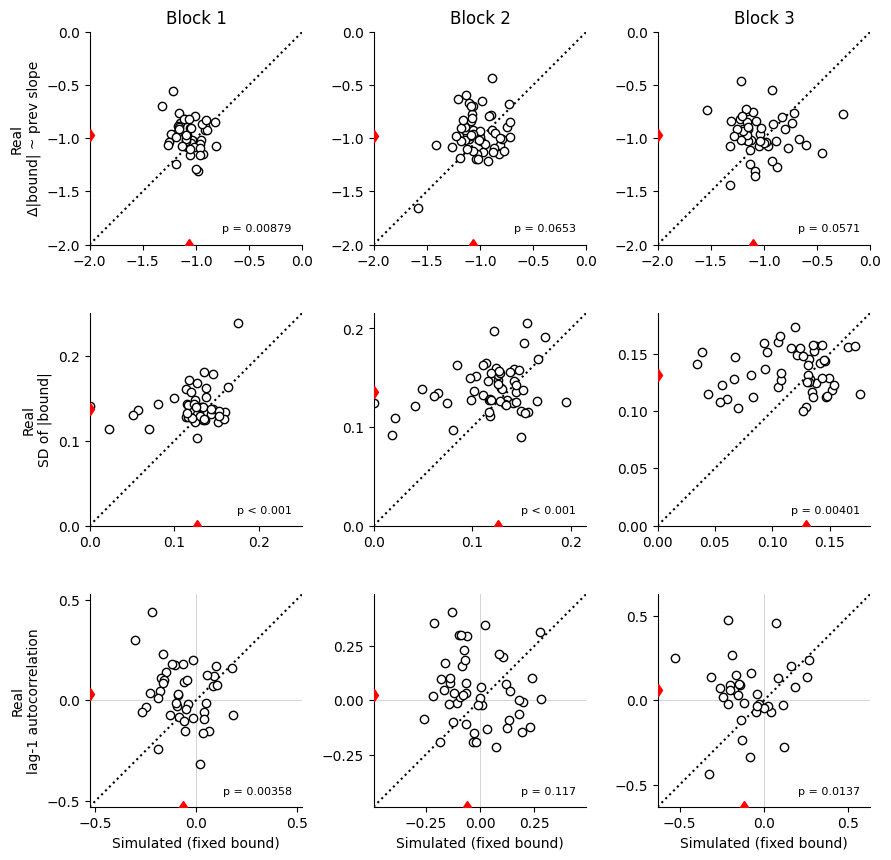

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure03_S03.pdf


In [9]:
def annotate_p(ax, p):
    txt = f'p = {p:.3g}' if p >= 0.001 else 'p < 0.001'
    ax.text(0.95, 0.05, txt, transform=ax.transAxes, ha='right', va='bottom', fontsize=8)


def add_median_markers(ax, xvals, yvals, edge):
    # Red diamond margin markers for the group medians of x and y, matching
    # the convention used in Figure02 panel 3 / Figure03 panel E: the median
    # of one axis's data is plotted at the opposite axis's edge value.
    ax.plot(edge, np.nanmedian(yvals), 'rd', markerfacecolor='r', zorder=5)
    ax.plot(np.nanmedian(xvals), edge, 'rd', markerfacecolor='r', zorder=5)


def square_axes(ax, lo, hi):
    # Square panels with identical tick marks/labels on both axes, since x and
    # y are the same metric (real vs. matched-simulated) on the same scale.
    ax.axis([lo, hi, lo, hi])
    ax.set_box_aspect(1)
    ticks = ax.get_xticks()
    ticks = ticks[(ticks >= lo) & (ticks <= hi)]
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)


# Per-subject marker size (ms=6) matches the default 'ko'/'ko' marker size used
# for per-subject scatter points elsewhere in this figure set (Figure02 panel C,
# Figure03 panel E, Figure04 panel A, Figure06's lower panels).
SUBJ_MS = 6

fig, axs = plt.subplots(3, len(BLOCKS), figsize=(3 * len(BLOCKS), 9))

for j, block in enumerate(BLOCKS):
    r = results[block]

    # Row 1: Δ|bound| ~ previous |bound| slope
    ax = axs[0, j]
    sr, ss = r['sr'], r['ss']
    lo, hi = -2, 0
    ax.plot([lo, hi], [lo, hi], 'k:')
    ax.plot(ss, sr, 'ko', mfc='w', ms=SUBJ_MS)
    add_median_markers(ax, ss, sr, lo)
    square_axes(ax, lo, hi)
    ax.set_title(f'Block {block}')
    if j == 0:
        ax.set_ylabel('Real\nΔ|bound| ~ prev slope')
    _, p_slope = scipy.stats.wilcoxon(sr, ss)
    annotate_p(ax, p_slope)

    # Row 2: SD of |bound|
    ax = axs[1, j]
    pr, ps = r['pr'], r['ps']
    hi2 = max(pr.max(), ps.max()) * 1.05
    ax.plot([0, hi2], [0, hi2], 'k:')
    ax.plot(ps, pr, 'ko', mfc='w', ms=SUBJ_MS)
    add_median_markers(ax, ps, pr, 0)
    square_axes(ax, 0, hi2)
    if j == 0:
        ax.set_ylabel('Real\nSD of |bound|')
    _, p_std = scipy.stats.wilcoxon(pr, ps)
    annotate_p(ax, p_std)

    # Row 3: lag-1 autocorrelation
    ax = axs[2, j]
    common = r['common']
    r1 = r['acf_real'][1].loc[common]
    s1 = r['acf_sim'][1].loc[common]
    ok = r1.notna() & s1.notna()
    r1_ok, s1_ok = r1[ok], s1[ok]
    m = max(0.05, pd.concat([r1_ok, s1_ok]).abs().max() * 1.2)
    ax.axhline(0, color='0.8', lw=0.6, zorder=0)
    ax.axvline(0, color='0.8', lw=0.6, zorder=0)
    ax.plot([-m, m], [-m, m], 'k:')
    ax.plot(s1_ok, r1_ok, 'ko', mfc='w', ms=SUBJ_MS)
    add_median_markers(ax, s1_ok, r1_ok, -m)
    square_axes(ax, -m, m)
    if j == 0:
        ax.set_ylabel('Real\nlag-1 autocorrelation')
    ax.set_xlabel('Simulated (fixed bound)')
    _, p_acf1 = scipy.stats.wilcoxon(r1_ok, s1_ok)
    annotate_p(ax, p_acf1)

for ax in axs.flat:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
out = FIGURES_DIR / 'Figure03_S03.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out}')